# Forecasting SPY

In this exercise, we build forecast regressions for SPY returns using multiple valuation signals. We then convert these forecasts into investment strategies and evaluate their performance.

A key focus is the distinction between **in-sample** and **out-of-sample** forecasting. In-sample results are biased because the model has seen the data it is predicting. Out-of-sample results use only information available at the time of the forecast, giving a more realistic assessment.

### Data

Use the data in `data/spy_forecasting_data.xlsx`.

* `spy returns` - monthly total returns for SPY
* `risk-free rate` - monthly risk-free rate (`T3M`)
* `signals` - valuation signals: `DP`, `EP`, `CAPE`, `BP`, `T10YR`, `CREDIT`, `VIX`

The frequency is monthly (`FREQ = 12`).

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression

#from cmds.portfolio import performanceMetrics, tailMetrics, get_ols_metrics

In [3]:
FILEPATH = 'spy_forecasting_data.xlsx'
FREQ = 12

SHEET_SPY = 'spy returns'
rets = pd.read_excel(FILEPATH, sheet_name=SHEET_SPY)
rets.set_index('date', inplace=True)

SHEET_RF = 'risk-free rate'
rf = pd.read_excel(FILEPATH, sheet_name=SHEET_RF)
rf.set_index('date', inplace=True)

SHEET_SIGNALS = 'signals'
sigs = pd.read_excel(FILEPATH, sheet_name=SHEET_SIGNALS)
sigs.set_index('date', inplace=True)

display(sigs.tail(3).style.format('{:,.2f}').format_index('{:%Y-%m-%d}'))

,DP,EP,CAPE,BP,T10YR,CREDIT,VIX
date,,,,,,,
2025-08-31,1.20,3.73,36.21,18.90,4.23,174.16,15.36
2025-09-30,1.17,3.60,37.38,18.30,4.15,164.17,16.28
2025-10-31,1.14,3.52,38.15,17.89,4.08,167.25,17.44


### Timing Convention

We estimate a forecast regression:

$$r_{t+1} = \alpha + \boldsymbol{\beta}' \boldsymbol{x}_t + \epsilon_{t+1}$$

The signals at time $t$ predict returns at $t+1$. To implement this in pandas:
- **Shift** the signals forward one period (`.shift()`) to create a lagged version.
- Align the lagged signals with returns so that pandas date-matching gives us the correct lag.

Date the forecast by the period being forecasted, not the period it was calculated.

***

# 1. In-Sample Forecast Regressions

### 1.1

Create a lagged version of the signals and align it with SPY returns.

Build in-sample forecasts using the following models:
* `Mean` - the expanding mean of SPY returns (shifted one period)
* `DP` - univariate regression on Dividend-Price ratio
* `EP` - univariate regression on Earnings-Price ratio
* `ALL` - multivariate regression on all available signals

Plot the forecasted returns over time for all models.

In [5]:
sigs_lag = sigs.shift(1)

df = rets.join(sigs_lag, how='inner')
df.head()

,SPY,DP,EP,CAPE,BP,T10YR,CREDIT,VIX
date,,,,,,,,
1993-02-28,0.010670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1993-03-31,0.022409,2.7997,4.100613,15.8223,42.574932,6.020,221.0,13.16
1993-04-30,-0.025587,2.7790,4.677947,16.0443,35.236082,6.024,218.6,12.53
1993-05-31,0.026969,2.8574,4.033836,15.5631,39.158868,6.009,216.1,12.42
1993-06-30,0.003667,2.7867,3.191707,16.3376,38.678734,6.149,211.1,13.47


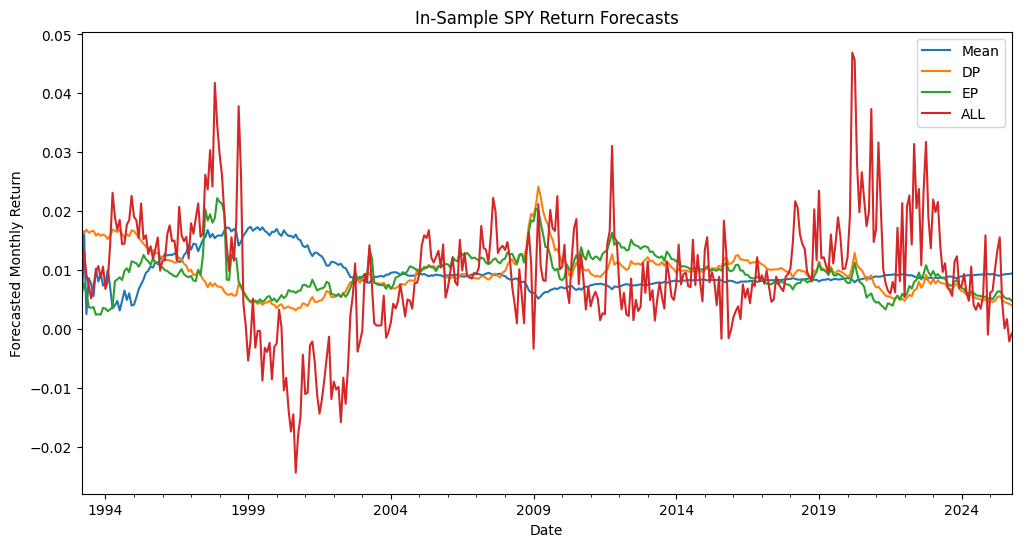

In [7]:
df = df.dropna()
y = df[rets.columns[0]]
X = df[sigs.columns]

forecasts = pd.DataFrame(index=df.index)
forecasts['Mean'] = rets.iloc[:, 0].expanding().mean().shift(1).reindex(df.index)

model_dp = LinearRegression()
model_dp.fit(X[['DP']], y)
forecasts['DP'] = model_dp.predict(X[['DP']])

model_ep = LinearRegression()
model_ep.fit(X[['EP']], y)
forecasts['EP'] = model_ep.predict(X[['EP']])

model_all = LinearRegression()
model_all.fit(X, y)
forecasts['ALL'] = model_all.predict(X)

forecasts.plot(figsize=(12, 6))
plt.title('In-Sample SPY Return Forecasts')
plt.xlabel('Date')
plt.ylabel('Forecasted Monthly Return')
plt.show()

### 1.2

Build investment strategies from the forecasts using:

$$w_t = 100 \cdot \hat{r}_{t+1}$$

The strategy return is:

$$r^{\text{strategy}}_{t+1} = w_t \cdot r^{\text{SPY}}_{t+1}$$

Also include a `Passive` strategy that simply holds SPY ($w_t = 1$).

Report:
* Annualized performance metrics (mean, vol, Sharpe) for all strategies
* Correlation matrix of strategy returns
* Cumulative return plot (log scale)

In [8]:
weights = 100 * forecasts

strat_rets = weights.mul(rets['SPY'], axis=0)

strat_rets['Passive'] = rets['SPY']

strat_rets = strat_rets.dropna()

strat_rets.head()

,Mean,DP,EP,ALL,Passive
date,,,,,
1993-03-31,0.023910,0.036777,0.013736,0.009939,0.022409
1993-04-30,-0.042320,-0.041590,-0.019646,-0.033761,-0.025587
1993-05-31,0.006734,0.045446,0.016048,0.024828,0.026969
1993-06-30,0.003159,0.005982,0.001354,0.002710,0.003667
1993-07-31,-0.003701,-0.008034,-0.001734,-0.002507,-0.004853


In [9]:
performance = pd.DataFrame({
    'Mean': strat_rets.mean() * FREQ,
    'Vol': strat_rets.std() * FREQ**0.5
})

performance['Sharpe'] = performance['Mean'] / performance['Vol']

display(performance.round(3))

,Mean,Vol,Sharpe
Mean,0.102,0.150,0.682
DP,0.121,0.156,0.780
EP,0.121,0.161,0.749
ALL,0.220,0.266,0.826
Passive,0.113,0.148,0.766


In [10]:
corr = strat_rets.corr()
display(corr.round(3))

,Mean,DP,EP,ALL,Passive
Mean,1.000,0.781,0.852,0.595,0.948
DP,0.781,1.000,0.949,0.700,0.915
EP,0.852,0.949,1.000,0.705,0.932
ALL,0.595,0.700,0.705,1.000,0.680
Passive,0.948,0.915,0.932,0.680,1.000


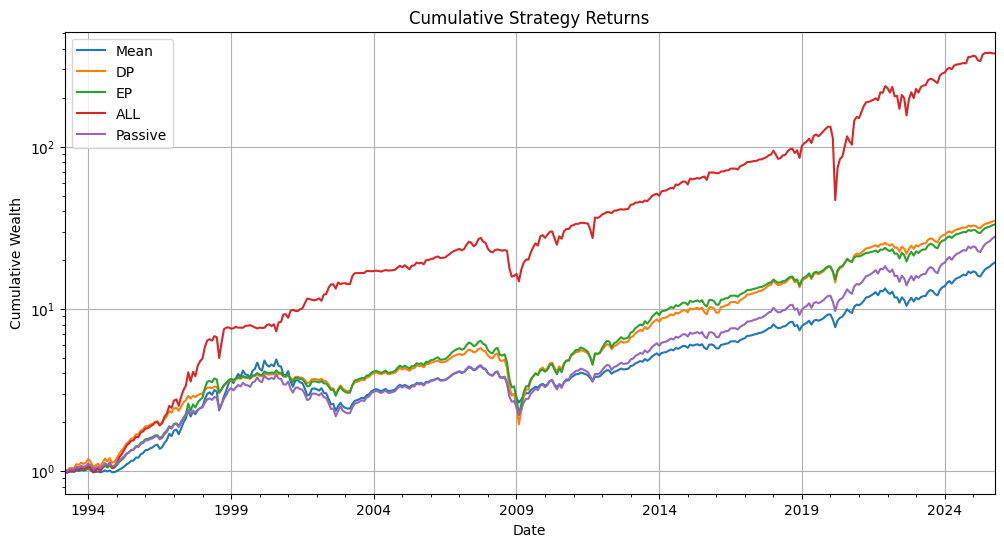

In [12]:
cumulative = (1 + strat_rets).cumprod()

ax = cumulative.plot(figsize=(12, 6), logy=True)

ax.set_title('Cumulative Strategy Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Wealth')
ax.grid(True)

plt.show()

### 1.3

Interpret the results. Which signal appears most useful? How do the active strategies compare to Passive in terms of Sharpe ratio? Are the active strategies highly correlated with each other?

The ALL model appears to be the most useful overall. It has the highest Sharpe ratio (0.826) and annualized return (22.0%), but it also has the highest volatility.

From the individual signals, DP performs the best. It has a Sharpe ratio of 0.780 compared to 0.749 for EP. ALL and DP outperform Passive (0.766) in terms of Sharpe ratio while EP and Mean (0.682) underperform Passive. The active strategies are highly correlated, but ALL has lower correlations with the other strategies. However, these results are in-sample so ALL's strong performance may be due to overfitting.

***

# 2. Out-of-Sample Forecasting

The in-sample results are biased. Now re-do the forecast regressions using an **expanding window** approach so that each forecast only uses data available at the time.

At each date $t$, estimate the regression using data from the start of the sample through $t$, then form the forecast for $t+1$.

Use a burn-in period of **5 years** (`BURN_YRS = 5`) before generating the first forecast.

### 2.1

Implement the out-of-sample expanding-window forecasts for the same models: `Mean`, `DP`, `EP`, and `ALL`.

Plot the OOS forecasts over time.

In [13]:
BURN_YRS = 5
burn = BURN_YRS * FREQ

forecasts_oos = pd.DataFrame(
    index=df.index,
    columns=['Mean', 'DP', 'EP', 'ALL'],
    dtype=float
)

for i in range(burn, len(df)):
    train = df.iloc[:i]
    test = df.iloc[[i]]

    y_train = train['SPY']

    forecasts_oos.loc[df.index[i], 'Mean'] = y_train.mean()

    model = LinearRegression()
    model.fit(train[['DP']], y_train)
    forecasts_oos.loc[df.index[i], 'DP'] = model.predict(test[['DP']])[0]

    model = LinearRegression()
    model.fit(train[['EP']], y_train)
    forecasts_oos.loc[df.index[i], 'EP'] = model.predict(test[['EP']])[0]

    model = LinearRegression()
    model.fit(train[sigs.columns], y_train)
    forecasts_oos.loc[df.index[i], 'ALL'] = model.predict(test[sigs.columns])[0]

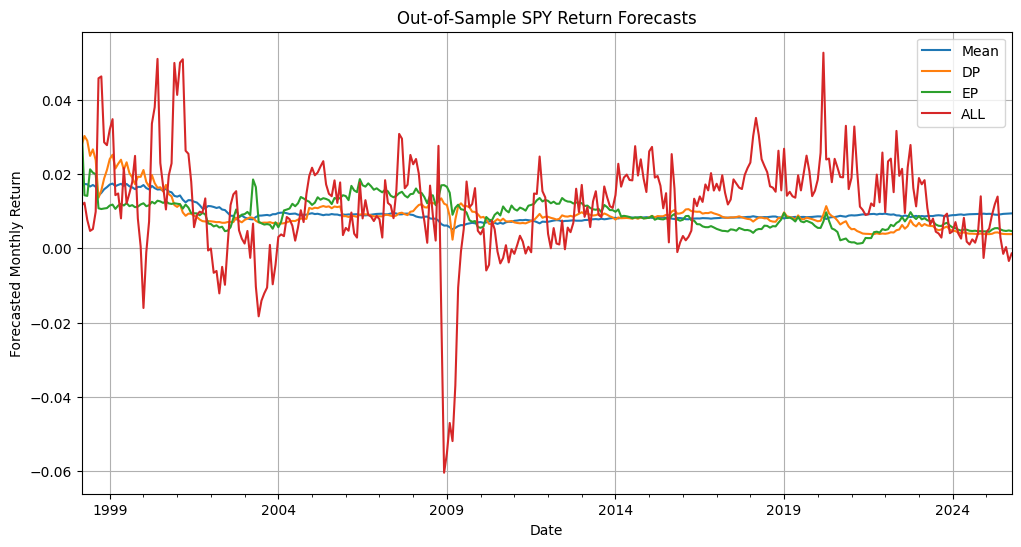

In [14]:
forecasts_oos.dropna().plot(figsize=(12, 6))

plt.title('Out-of-Sample SPY Return Forecasts')
plt.xlabel('Date')
plt.ylabel('Forecasted Monthly Return')
plt.grid(True)
plt.show()

### 2.2

Build the investment strategies from the OOS forecasts (using $w_t = 100 \cdot \hat{r}_{t+1}$) and report the same performance metrics as in Section 1.

Report:
* OOS $R^2$ for each model, using the expanding mean as the null forecast:

$$R^2_{\text{OOS}} = 1 - \frac{\text{MSE}_{\text{forecast}}}{\text{MSE}_{\text{null}}}$$

* Annualized performance metrics
* Cumulative returns (log scale)
* Correlation matrix

In [15]:
oos = forecasts_oos.dropna()
y_oos = rets.loc[oos.index, 'SPY']

mse_null = ((y_oos - oos['Mean'])**2).mean()

r2_oos = {}

for col in oos.columns:
    mse = ((y_oos - oos[col])**2).mean()
    r2_oos[col] = 1 - mse / mse_null

display(pd.Series(r2_oos, name='OOS R2').round(4))

,OOS R2
Mean,0.0000
DP,-0.0054
EP,-0.0039
ALL,-0.0610


In [16]:
weights_oos = 100 * oos

strat_rets_oos = weights_oos.mul(y_oos, axis=0)

strat_rets_oos['Passive'] = y_oos

strat_rets_oos.head()

,Mean,DP,EP,ALL,Passive
date,,,,,
1998-03-31,0.081860,0.135215,0.159550,0.056374,0.048761
1998-04-30,0.022145,0.038691,0.018267,0.015705,0.012791
1998-05-31,-0.035803,-0.060188,-0.029297,-0.015857,-0.020769
1998-06-30,0.070852,0.106007,0.090586,0.019936,0.042590
1998-07-31,-0.023029,-0.036002,-0.027505,-0.007003,-0.013513


In [17]:
performance_oos = pd.DataFrame({
    'Mean': strat_rets_oos.mean() * FREQ,
    'Vol': strat_rets_oos.std() * FREQ**0.5
})

performance_oos['Sharpe'] = (
    performance_oos['Mean'] / performance_oos['Vol'])

display(performance_oos.round(3))

,Mean,Vol,Sharpe
Mean,0.082,0.151,0.541
DP,0.081,0.166,0.488
EP,0.083,0.165,0.503
ALL,0.146,0.356,0.410
Passive,0.097,0.153,0.634


In [18]:
corr_oos = strat_rets_oos.corr()
display(corr_oos.round(3))

,Mean,DP,EP,ALL,Passive
Mean,1.000,0.952,0.909,0.586,0.951
DP,0.952,1.000,0.941,0.527,0.897
EP,0.909,0.941,1.000,0.430,0.921
ALL,0.586,0.527,0.430,1.000,0.530
Passive,0.951,0.897,0.921,0.530,1.000


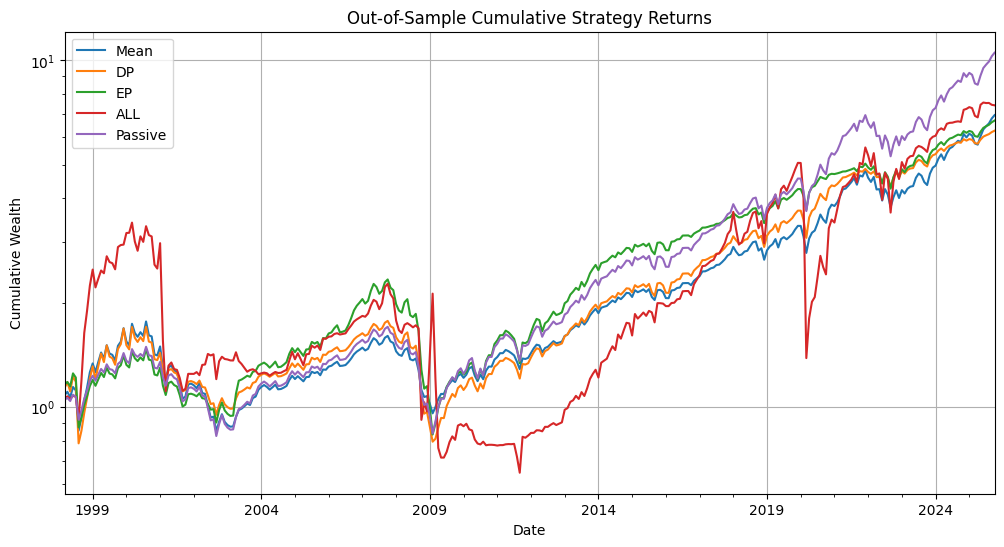

In [21]:
cumulative_oos = (1 + strat_rets_oos).cumprod()

ax = cumulative_oos.plot(figsize=(12, 6), logy=True)

ax.set_title('Out-of-Sample Cumulative Strategy Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Wealth')
ax.grid(True)

plt.show()

### 2.3

Compare the in-sample and out-of-sample results. Do the signals that looked good in-sample still look good out-of-sample? Is the OOS $R^2$ positive for any model?

We can see that the signals that performed well in-sample do not maintain their performance OOS. In-sample, ALL and DP had the highest Sharpe ratios. OOS, Passive has the highest Sharpe ratio (0.634), while ALL and DP have the lowest (0.410 and 0.488).

None of the regression models have a positive OOS R^2 which makes sense since it's hard to beat the naive forecast. These results support that the good results from the in-sample ALL foreacst was driven by overfitting and not genuine predictive power. This is why it's important to test OOS.

***

# 3. Extension: Machine Learning Forecasts

Compare the OLS approach with machine learning methods. Use all signals as features and compare:
* `OLS` - linear regression (same as `ALL` above)
* `Random Forest` - with `max_depth=5`, `n_estimators=100`
* `NN` - neural network (`MLPRegressor` with `hidden_layer_sizes=(50,)`)

For the neural network, standardize the features and target before training (using `StandardScaler`), and inverse-transform the predictions back to the original scale.

In [22]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

### 3.1

First, estimate and evaluate the ML models **in-sample** alongside OLS and the expanding mean.

Report the performance metrics and correlation of the resulting strategies. Plot the cumulative returns.

Note that the ML models may overfit. How does in-sample $R^2$ compare between OLS and the ML methods?

In [25]:
X = df[sigs.columns]
y = df['SPY']

forecasts_ml = pd.DataFrame(index=df.index)
forecasts_ml['Mean'] = rets['SPY'].expanding().mean().shift(1).reindex(df.index)

# OLS
ols = LinearRegression()
ols.fit(X, y)
forecasts_ml['OLS'] = ols.predict(X)

# Random Forest
rf_model = RandomForestRegressor(
    max_depth=5,
    n_estimators=100,
    random_state=42
)

rf_model.fit(X, y)
forecasts_ml['RF'] = rf_model.predict(X)

# Neural Network
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.to_numpy().reshape(-1, 1)).ravel()

nn_model = MLPRegressor(
    hidden_layer_sizes=(50,),
    random_state=42,
    max_iter=2000
)

nn_model.fit(X_scaled, y_scaled)
nn_pred_scaled = nn_model.predict(X_scaled)

forecasts_ml['NN'] = scaler_y.inverse_transform(
    nn_pred_scaled.reshape(-1, 1)
).ravel()

r2_results = {}

for col in ['OLS', 'RF', 'NN']:
    r2_results[col] = r2_score(y, forecasts_ml[col])

display(pd.Series(r2_results, name='In-Sample R^2').round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


,In-Sample R^2
OLS,0.0520
RF,0.2942
NN,0.5555


In [26]:
weights_ml = 100 * forecasts_ml

strat_rets_ml = weights_ml.mul(y, axis=0)

strat_rets_ml['Passive'] = y

strat_rets_ml = strat_rets_ml.dropna()

In [27]:
performance_ml = pd.DataFrame({
    'Mean': strat_rets_ml.mean() * FREQ,
    'Vol': strat_rets_ml.std() * FREQ**0.5
})

performance_ml['Sharpe'] = (
    performance_ml['Mean'] / performance_ml['Vol'])

display(performance_ml.round(3))

,Mean,Vol,Sharpe
Mean,0.102,0.150,0.682
OLS,0.220,0.266,0.826
RF,0.507,0.414,1.226
NN,1.119,0.667,1.678
Passive,0.113,0.148,0.766


In [28]:
corr_ml = strat_rets_ml.corr()
display(corr_ml.round(3))

,Mean,OLS,RF,NN,Passive
Mean,1.000,0.595,0.155,0.048,0.948
OLS,0.595,1.000,0.301,0.276,0.680
RF,0.155,0.301,1.000,0.814,0.174
NN,0.048,0.276,0.814,1.000,0.055
Passive,0.948,0.680,0.174,0.055,1.000


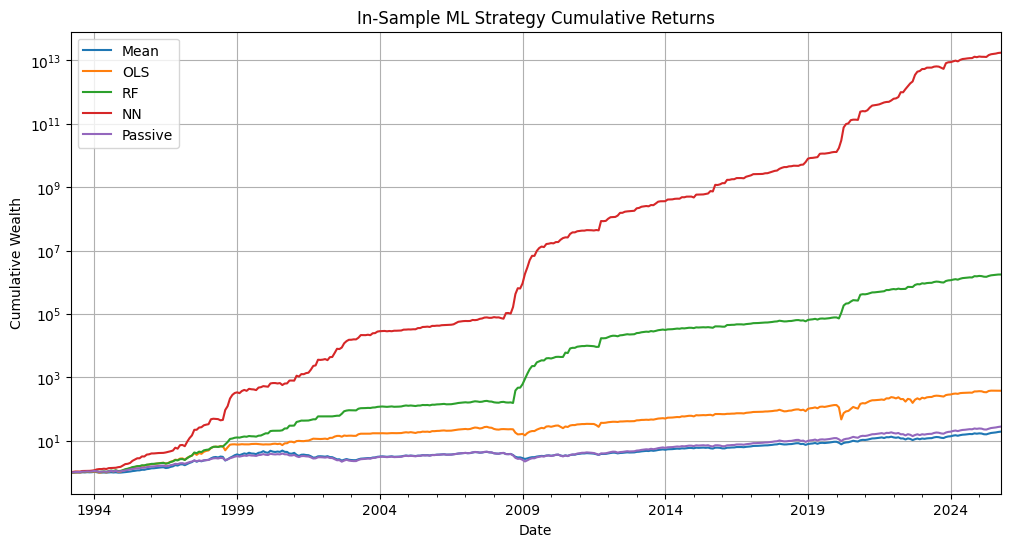

In [29]:
cumulative_ml = (1 + strat_rets_ml).cumprod()

ax = cumulative_ml.plot(figsize=(12, 6), logy=True)

ax.set_title('In-Sample ML Strategy Cumulative Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Wealth')
ax.grid(True)

plt.show()

### 3.2

Now estimate the ML models **out-of-sample** using the same expanding-window approach as Section 2.

Report the same metrics. Do the ML methods outperform OLS out-of-sample? Does the in-sample advantage survive?

In [30]:
forecasts_ml_oos = pd.DataFrame(
    index=df.index,
    columns=['Mean', 'OLS', 'RF', 'NN'],
    dtype=float)

for i in range(burn, len(df)):

    train = df.iloc[:i]
    test = df.iloc[[i]]

    X_train = train[sigs.columns]
    y_train = train['SPY']
    X_test = test[sigs.columns]

    forecasts_ml_oos.loc[df.index[i], 'Mean'] = y_train.mean()

    # OLS
    ols = LinearRegression()
    ols.fit(X_train, y_train)
    forecasts_ml_oos.loc[df.index[i], 'OLS'] = ols.predict(X_test)[0]

    # Random Forest
    rf_model = RandomForestRegressor(
        max_depth=5,
        n_estimators=100,
        random_state=42)

    rf_model.fit(X_train, y_train)
    forecasts_ml_oos.loc[df.index[i], 'RF'] = rf_model.predict(X_test)[0]

    # Neural Network
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled = scaler_X.transform(X_test)

    y_train_scaled = scaler_y.fit_transform(
        y_train.to_numpy().reshape(-1, 1)
    ).ravel()

    nn_model = MLPRegressor(
        hidden_layer_sizes=(50,),
        random_state=42,
        max_iter=2000)

    nn_model.fit(X_train_scaled, y_train_scaled)

    pred_scaled = nn_model.predict(X_test_scaled)

    forecasts_ml_oos.loc[df.index[i], 'NN'] = (
        scaler_y.inverse_transform(pred_scaled.reshape(-1, 1))[0, 0])

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perce

In [32]:
oos_ml = forecasts_ml_oos.dropna()
y_oos_ml = df.loc[oos_ml.index, 'SPY']

mse_null = ((y_oos_ml - oos_ml['Mean'])**2).mean()

r2_ml_oos = {}

for col in oos_ml.columns:
    mse = ((y_oos_ml - oos_ml[col])**2).mean()
    r2_ml_oos[col] = 1 - mse / mse_null

display(pd.Series(r2_ml_oos, name='OOS R^2').round(4))

,OOS R^2
Mean,0.0000
OLS,-0.0610
RF,-0.1877
NN,-1.1838


In [33]:
weights_ml_oos = 100 * oos_ml

strat_rets_ml_oos = weights_ml_oos.mul(y_oos_ml, axis=0)

strat_rets_ml_oos['Passive'] = y_oos_ml

In [35]:
performance_ml_oos = pd.DataFrame({
    'Mean': strat_rets_ml_oos.mean() * FREQ,
    'Vol': strat_rets_ml_oos.std() * FREQ**0.5})

performance_ml_oos['Sharpe'] = (
    performance_ml_oos['Mean'] / performance_ml_oos['Vol'])

display(performance_ml_oos.round(3))

,Mean,Vol,Sharpe
Mean,0.082,0.151,0.541
OLS,0.146,0.356,0.410
RF,-0.081,0.324,-0.250
NN,-0.369,1.139,-0.324
Passive,0.097,0.153,0.634


In [36]:
corr_ml_oos = strat_rets_ml_oos.corr()
display(corr_ml_oos.round(3))

,Mean,OLS,RF,NN,Passive
Mean,1.000,0.586,0.249,0.201,0.951
OLS,0.586,1.000,0.563,0.202,0.530
RF,0.249,0.563,1.000,0.439,0.226
NN,0.201,0.202,0.439,1.000,0.249
Passive,0.951,0.530,0.226,0.249,1.000


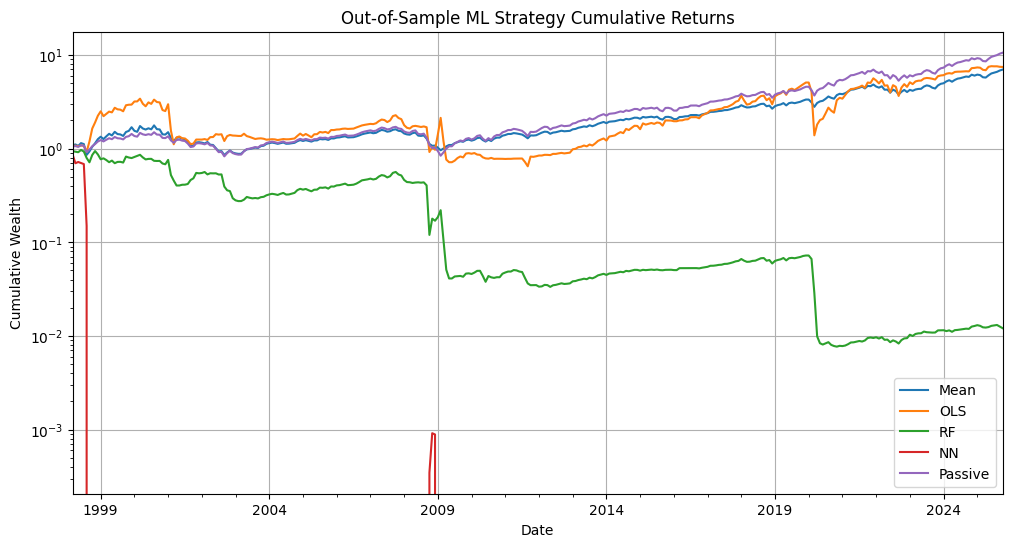

In [38]:
cumulative_ml_oos = (1 + strat_rets_ml_oos).cumprod()

ax = cumulative_ml_oos.plot(figsize=(12, 6), logy=True)

ax.set_title('Out-of-Sample ML Strategy Cumulative Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Wealth')
ax.grid(True)

plt.show()

In [39]:
r2_comparison = pd.DataFrame({
    'In-Sample R^2': pd.Series(r2_results),
    'OOS R^2': pd.Series(r2_ml_oos)})

display(r2_comparison.round(4))

,In-Sample R^2,OOS R^2
Mean,NaN,0.0000
NN,0.5555,-1.1838
OLS,0.0520,-0.0610
RF,0.2942,-0.1877


In [40]:
strat_rets_ml_oos.min()

,0
Mean,-0.233954
OLS,-0.656556
RF,-0.704043
NN,-4.434352
Passive,-0.165187


### Hints

* Use `.shift()` and `.dropna()` to create the lagged signals.
* For the expanding mean baseline: `rets[['SPY']].expanding().mean().shift(1).dropna()`
* In the OOS loop, at each time $t$, fit the model on `sigs_lag.loc[:t]` and `spy.loc[:t]`, then predict using `sigs.loc[t]` (the unlagged signal at $t$, which forecasts $t+1$).
* After the loop, shift the OOS forecasts forward one period so timestamps reflect the date being forecasted.
* For the neural network OOS, fit a new `StandardScaler` at each step using only data through $t$.
* `sklearn.ensemble.RandomForestRegressor` and `sklearn.neural_network.MLPRegressor` are the relevant imports.
* The OOS ML loop will be slow (many regressions). This is expected.

The ML models do not outperform OLS OOS, despite having higher in-sample R^2. The neural network has the highest in-sample R² (0.5555), but it has the worst OOS R^2 (-1.1838). The ML strategies also have negative Sharpe ratios (-0.250 for RF and -0.324 for NN), compared to 0.410 for OLS and 0.634 for Passive. These results suggest that the additional flexibility of the ML models leads to substantial overfitting because the strong performance is only seen in-sample.

# GMO

*Case: Grantham, Mayo, and Van Otterloo, 2012: Estimating the Equity Risk Premium
[9-211-051].*

# 2 Analyzing GMO's Flagship Fund

### Data
This section utilizes data in the file `gmo_returns_weekly.xlsx`.
* `gmo`: total returns on two GMO funds
* `benchmarks`: ETFs spanning the asset classes considered in the case
* `indexes`: two indexes which are listed in the description of `GMWAX`
* `info`: more info on the

Use `SHV` as the risk-free rate to calculate the **excess** returns.

In [41]:
filename = 'gmo_returns_weekly.xlsx'
TICK_RF = 'USGG3M'

# Load data
gmo = pd.read_excel(filename, sheet_name='gmo', index_col=0, parse_dates=True)
benchmarks = pd.read_excel(filename, sheet_name='benchmarks', index_col=0, parse_dates=True)
indexes = pd.read_excel(filename, sheet_name='indexes', index_col=0, parse_dates=True)
rates = pd.read_excel(filename, sheet_name='rates', index_col=0, parse_dates=True)
info = pd.read_excel(filename, sheet_name='info').set_index('Ticker')


if '_daily' in filename:
    ann_factor = 252
elif '_weekly' in filename:
    ann_factor = 52
elif '_monthly' in filename:
    ann_factor = 12
else:
    # Default to daily if no tag found
    ann_factor = 252


In [42]:
info.style.format({
    "Company Description": lambda x: (x if pd.isnull(x) else (x[:75] + '...' if len(x) > 100 else x)),
    info.columns[-2]: '${:,.0f}'.format,
    info.columns[-1]: '{:.2f}%'.format
}, na_rep='')

,Name,Company Description,Fund Total Assets,Dividend Yield
Ticker,,,,
GMWAX,GMO Global Asset Allocation Fu,GMO Global Asset Allocation Fund seeks total return greater than that of it...,$466,4.24%
GBMFX,GMO Benchmark-Free Allocation,GMO Benchmark-Free Allocation Fund seeks a positive return by investing in ...,"$2,427",4.31%
GQETX,GMO Quality Fund,GMO Quality Fund seeks total return by investing in equities believed to be...,"$11,914",6.48%
GMGEX,GMO Global Equity Allocation F,GMO Global Equity Allocation Fund seeks a total return greater than its ben...,$610,4.30%
SPY,SPDR S&P 500 ETF Trust,SPDR S&P 500 ETF Trust is an exchange-traded fund incorporated in the USA. ...,"$693,035",1.08%
EFA,iShares MSCI EAFE ETF,iShares MSCI EAFE ETF is an exchange-traded fund incorporated in the USA. T...,"$68,792",2.71%
IJR,iShares Core S&P Small-Cap ETF,iShares Core S&P Small-Cap ETF is an exchange-traded fund incorporated in t...,"$84,951",1.97%
GWX,SPDR S&P International Small C,SPDR S&P International Small Cap ETF is an exchange-traded fund incorporate...,$774,2.22%
EEM,iShares MSCI Emerging Markets,iShares MSCI Emerging Markets ETF is an exchange-traded fund incorporated i...,"$20,902",2.14%


### 1. Benchmarks

Construct what we will call the `GBI` (GMWAX Benchmark Index). The `GBI` is constructed as (per detailed in the `info` tab)
* 65% of `MXWD`
* 35% of `LBUSTRUU`

Calculate excess returns of `GMWAX`, `GBI` and of `SPY`.

For all three, estimate the full-sample (annualized)
* mean
* vol
* Sharpe

Also report
* minimum return
* 5th percentile
* maximum drawdown

Also report the correlation matrix.

In [43]:
gbi = 0.65 * indexes['MXWD'] + 0.35 * indexes['LBUSTRUU']
gbi.name = 'GBI'

In [47]:
rf_weekly = rates['USGG3M'] / ann_factor

returns = pd.concat([
    gmo['GMWAX'],
    gbi,
    benchmarks['SPY'],
    rf_weekly.rename('RF')
], axis=1).dropna()

excess = returns[['GMWAX', 'GBI', 'SPY']].sub(
    returns['RF'], axis=0)

display(excess.head())

,GMWAX,GBI,SPY
1996-11-01,-0.002992,0.002621,0.003008
1996-11-08,0.020046,0.019284,0.039066
1996-11-15,0.008826,0.007846,0.007313
1996-11-22,0.011642,0.007589,0.014415
1996-11-29,-0.001945,0.001296,0.010238


In [49]:
performance = pd.DataFrame({
    'Mean': excess.mean() * ann_factor,
    'Vol': excess.std() * ann_factor**0.5})

performance['Sharpe'] = performance['Mean'] / performance['Vol']
performance['Min'] = excess.min()
performance['5th Percentile'] = excess.quantile(0.05)

wealth = (1 + returns[['GMWAX', 'GBI', 'SPY']]).cumprod()
peak = wealth.cummax()
drawdown = wealth / peak - 1
performance['Max Drawdown'] = drawdown.min()

display(performance.round(3))

,Mean,Vol,Sharpe,Min,5th Percentile,Max Drawdown
GMWAX,0.049,0.104,0.467,-0.105,-0.022,-0.304
GBI,0.054,0.111,0.484,-0.137,-0.022,-0.398
SPY,0.089,0.178,0.500,-0.198,-0.039,-0.546


In [50]:
corr = excess.corr()
display(corr.round(3))

,GMWAX,GBI,SPY
GMWAX,1.000,0.863,0.778
GBI,0.863,1.000,0.930
SPY,0.778,0.930,1.000


### 2. Attribution

Estimate an attribution LFD of `GMWAX` on
* `SPY`
* `GBI`

That is, estimate a univariate regression for each.

Report the
* alpha (annualized)
* beta
* r-squared

In [55]:
results = pd.DataFrame(index=['SPY', 'GBI'],
                       columns=['Alpha', 'Beta', 'R^2'])

y = excess['GMWAX']

for benchmark in ['SPY', 'GBI']:
    X = excess[[benchmark]]

    model = LinearRegression()
    model.fit(X, y)

    results.loc[benchmark, 'Alpha'] = model.intercept_ * ann_factor
    results.loc[benchmark, 'Beta'] = model.coef_[0]
    results.loc[benchmark, 'R^2'] = model.score(X, y)

display(results.astype(float).round(4))

,Alpha,Beta,R^2
SPY,0.0081,0.4550,0.6051
GBI,0.0051,0.8126,0.7439


### 3. Interpretation

What do you conclude about `GMWAX` relative performance?
* Is it low-beta to the market?
* Does it track the index?
* Does `GMWAX` seem to earn alpha for its investors?

GMWAX has low market exposure seen by the beta of 0.455 to SPY, suggesting it is less sensitive to the market's movements. It tracks GBI more closely than SPY with an R^2 of 0.744 compared to 0.605, but it's not a perfect replication of either index.

GMWAX generates positive annualized alpha of 0.81% relative to SPY and 0.51% relative to GBI so it slightly outperforms. However, it has a lower Sharpe ratio (0.467) compared to GBI (0.484) and SPY (0.500), and its excess return (4.9%) is also lower. The positive is that GMWAX offers lower volatility (10.4%) and smaller maximum drawdowns (-30.4%). Overall, GMWAX is effective at reducing market risk and downside exposure, but its positive alpha is relatively small so it doesn't add much value to investors in terms of returns.

# 3. Other GMO Funds

### 1.

Report the correlation matrix of all GMO funds, along with `SPY` and the provided indexes.

Plot their cumulative returns.

In [56]:
all_rets = pd.concat([
    gmo,
    benchmarks[['SPY']],
    indexes
], axis=1).dropna()

display(all_rets.head())

,GMWAX,GBMFX,GQETX,GMGEX,SPY,MXWD,LBUSTRUU
2004-02-13,0.022748,0.019822,0.002000,0.013900,0.005942,0.011530,0.004415
2004-02-20,0.000000,-0.006347,-0.001497,-0.006403,-0.002172,-0.003250,-0.001582
2004-02-27,-0.006406,0.005190,-0.003998,-0.002727,0.001218,-0.001133,0.005280
2004-03-05,0.011103,0.017077,0.009533,0.024938,0.011824,0.013523,0.006532
2004-03-12,-0.018420,-0.024209,-0.030318,-0.035163,-0.032651,-0.036957,0.002525


In [57]:
corr_all = all_rets.corr()
display(corr_all.round(3))

,GMWAX,GBMFX,GQETX,GMGEX,SPY,MXWD,LBUSTRUU
GMWAX,1.000,0.939,0.869,0.952,0.876,0.930,0.119
GBMFX,0.939,1.000,0.756,0.876,0.755,0.817,0.079
GQETX,0.869,0.756,1.000,0.884,0.943,0.893,0.038
GMGEX,0.952,0.876,0.884,1.000,0.900,0.935,0.021
SPY,0.876,0.755,0.943,0.900,1.000,0.952,0.006
MXWD,0.930,0.817,0.893,0.935,0.952,1.000,0.050
LBUSTRUU,0.119,0.079,0.038,0.021,0.006,0.050,1.000


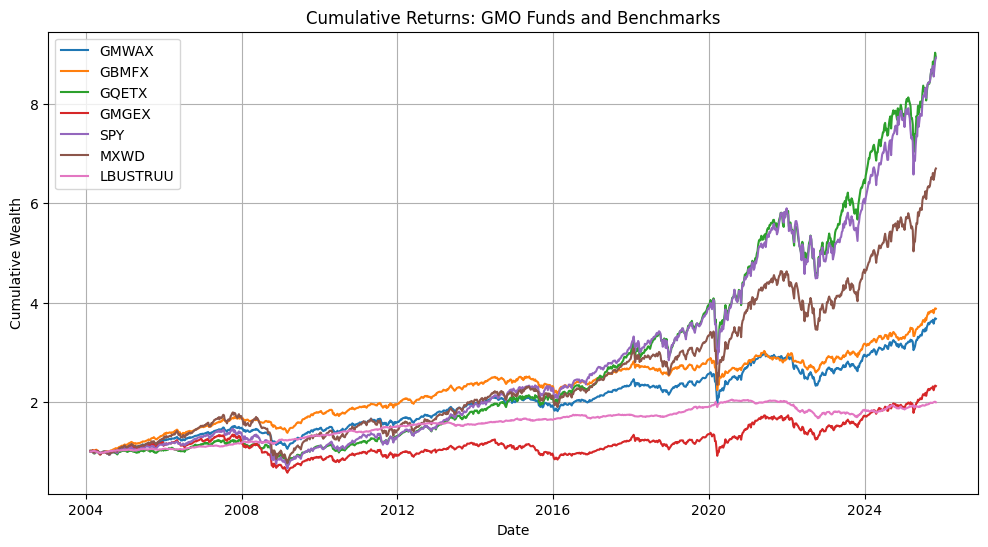

In [58]:
cumulative = (1 + all_rets).cumprod()

plt.figure(figsize=(12, 6))

for col in cumulative.columns:
    plt.plot(cumulative.index, cumulative[col], label=col)

plt.title('Cumulative Returns: GMO Funds and Benchmarks')
plt.xlabel('Date')
plt.ylabel('Cumulative Wealth')
plt.legend()
plt.grid(True)
plt.show()

### 2.
Re-do the analysis of `Section 2` for all GMO funds.

#### Footnote
No need to compare to the `GBI`, as it is not provided as a benchmark for the others. You could benchmark `GMGEX` to `MXWD`, as it is listed as the primary benchmark. The others don't list a benchmark.

In [59]:
all_data = pd.concat([
    gmo,
    benchmarks[['SPY']],
    indexes[['MXWD']],
    rf_weekly.rename('RF')
], axis=1)

all_excess = all_data.drop(columns='RF').sub(
    all_data['RF'], axis=0)

display(all_excess.head())

,GMWAX,GBMFX,GQETX,GMGEX,SPY,MXWD
1996-01-05,NaN,NaN,NaN,NaN,NaN,NaN
1996-01-12,NaN,NaN,NaN,NaN,-0.023065,-0.019012
1996-01-19,NaN,NaN,NaN,NaN,0.016137,0.004117
1996-01-26,NaN,NaN,NaN,NaN,0.014833,0.001245
1996-02-02,NaN,NaN,NaN,NaN,0.021637,0.021338


In [61]:
results_all = []

for fund in gmo.columns:
    data = all_excess[[fund, 'SPY']].dropna()

    X = data[['SPY']]
    y = data[fund]

    model = LinearRegression()
    model.fit(X, y)

    results_all.append({
        'Fund': fund,
        'Benchmark': 'SPY',
        'Alpha': model.intercept_ * ann_factor,
        'Beta': model.coef_[0],
        'R^2': model.score(X, y)
    })

data = all_excess[['GMGEX', 'MXWD']].dropna()

model = LinearRegression()
model.fit(data[['MXWD']], data['GMGEX'])

results_all.append({
    'Fund': 'GMGEX',
    'Benchmark': 'MXWD',
    'Alpha': model.intercept_ * ann_factor,
    'Beta': model.coef_[0],
    'R^2': model.score(data[['MXWD']], data['GMGEX'])
})

results_all = pd.DataFrame(results_all).set_index(['Fund', 'Benchmark'])

display(results_all.round(4))

Alpha    Beta     R^2
Fund  Benchmark                        
GMWAX SPY        0.0081  0.4550  0.6051
GBMFX SPY        0.0209  0.3430  0.5624
GQETX SPY        0.0153  0.8021  0.8900
GMGEX SPY       -0.0354  0.7438  0.7159
      MXWD      -0.0295  0.8369  0.8110

### 3. Comparing the GMO Funds

How similar are the GMO funds?

Which do you think is the most attractive investment product?

The GMO funds are highly correlated with one another suggesting that they share substantial exposure to similar market factors. However, their sensitivities to the market are very different. GBMFX has the lowest SPY beta (0.343), followed by GMWAX (0.455), while GQETX (0.802) and GMGEX (0.744) have greater equity market exposure.

I would consider GBMFX the most attractive investment product for an investor prioritizing risk-adjusted performance and diversification because it has the lowest market beta (0.3430) and the highest estimated annualized alpha relative to SPY (2.09%). GQETX has the best cumulative returns, but its high beta (0.802) and R² (0.890) suggest that a lot of its performance is explained by equity market exposure and investors look for investments that don't move with the equity market.

# 4. GMO Across Subsamples

### 1. Subsamples

For all the GMO funds as well as SPY, calculate the Sharpe ratio for the following subsamples.
* start to 2011
* 2012 to end

Do we see outperformance in GMO funds across either subsumple? Both?

In [63]:
funds = list(gmo.columns) + ['SPY']

pre_2012 = all_excess.loc[:'2011-12-31', funds]
post_2012 = all_excess.loc['2012-01-01':, funds]

sharpe_pre = pre_2012.mean() / pre_2012.std() * np.sqrt(ann_factor)
sharpe_post = post_2012.mean() / post_2012.std() * np.sqrt(ann_factor)

sharpe_subsamples = pd.DataFrame({
    'Start to 2011': sharpe_pre,
    '2012 to End': sharpe_post})

display(sharpe_subsamples.round(3))

,Start to 2011,2012 to End
GMWAX,0.437,0.505
GBMFX,1.143,0.459
GQETX,0.173,0.913
GMGEX,-0.011,0.412
SPY,0.263,0.867


No GMO fund consistently outperformed SPY across both subsamples. GBMFX's strong performance before 2012 did not continue and GQETX's outperformance started after 2012. This suggests that GMO's relative performance is very dependent on market conditions.

### 2. Subsample Info Ratios

For all the GMO funds calculate the **Info** ratio relative to `SPY` for the following subsamples.
* start to 2011
* 2012 to end

Do we see outperformance in GMO funds across either subsumple? Both?

In [64]:
funds = gmo.columns
active = all_excess[funds].sub(all_excess['SPY'], axis=0)

pre = active.loc[:'2011-12-31']
post = active.loc['2012-01-01':]

ir_pre = pre.mean() / pre.std() * np.sqrt(ann_factor)
ir_post = post.mean() / post.std() * np.sqrt(ann_factor)

ir_results = pd.DataFrame({
    'Start to 2011': ir_pre,
    '2012 to End': ir_post})

display(ir_results.round(3))

,Start to 2011,2012 to End
GMWAX,0.016,-1.008
GBMFX,0.280,-0.903
GQETX,-0.080,-0.069
GMGEX,-0.387,-0.994


Before 2012, GMWAX and GBMFX outperformed SPY with positive information ratios of 0.016 and 0.280. After 2012, all GMO funds had negative information ratios suggesting underperformance relative to SPY. This also shows that no GMO fund consistently outperformed SPY across both periods.

### 3.

Compare the cumulative returns from `2001` to `2010` of
* the GMO funds
* `SPY`
* Treasuries via `TLT`
* the risk-free rate for the time period

Is the GMO case correct that equities underperformed this period?

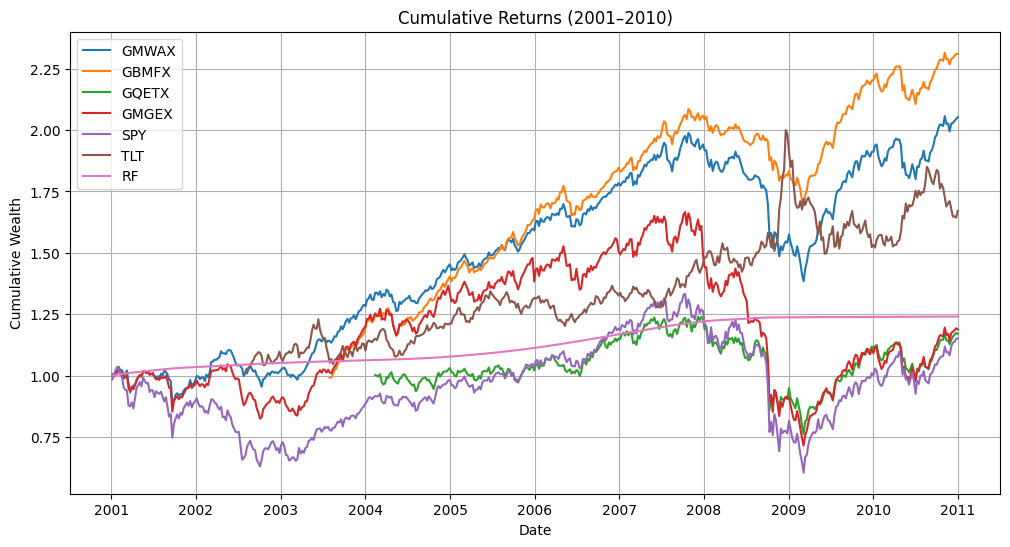

In [65]:
rets = pd.concat([
    gmo,
    benchmarks[['SPY', 'TLT']],
    rf_weekly.rename('RF')
], axis=1)

rets = rets.loc['2001':'2010']
cumulative = (1 + rets).cumprod()

plt.figure(figsize=(12, 6))

for col in cumulative.columns:
    plt.plot(cumulative.index, cumulative[col], label=col)

plt.title('Cumulative Returns (2001–2010)')
plt.xlabel('Date')
plt.ylabel('Cumulative Wealth')
plt.legend()
plt.grid(True)
plt.show()

In [66]:
total_returns = cumulative.iloc[-1] - 1
display(total_returns.sort_values(ascending=False).round(3))

,2010-12-31
GBMFX,1.310
GMWAX,1.052
TLT,0.670
RF,0.241
GMGEX,0.188
GQETX,0.171
SPY,0.152


Yes, the GMO case is supported by the results. From 2001 to 2010, SPY returned only 15.2% which underperformed Treasuries (67.0%) and the risk-free rate (24.1%). GMWAX and GBMFX performed much better, returning 105.2% and 131.0%. So while equities delivered weak returns during this period, GMO's allocation strategies were more successful.

# 5. Factor Exposures

### 1.

Estimate a LFD of `GMWAX` on the following...

* `SPY`
* `EFA`
* `EEM`
* `TLT`
* `TIP`

(GMO case considers additional benchmarks such as foreign bonds, small stocks, etc. They don't add much to this analysis.)

Report the
* alpha
* beta
* r-squared

In [67]:
factors = ['SPY', 'EFA', 'EEM', 'TLT', 'TIP']

X = benchmarks[factors].sub(rf_weekly, axis=0)
y = gmo['GMWAX'] - rf_weekly

data = pd.concat([y.rename('GMWAX'), X], axis=1).dropna()

model = LinearRegression()
model.fit(data[factors], data['GMWAX'])

results = pd.DataFrame({
    'Beta': model.coef_
}, index=factors)

display(results.round(4))

print('Alpha:', model.intercept_ * ann_factor)
print('R-squared:', model.score(data[factors], data['GMWAX']))

,Beta
SPY,0.1577
EFA,0.2840
EEM,0.0644
TLT,0.0281
TIP,0.0891


Alpha: 0.006465084276993991
R-squared: 0.8859617949455214


### 2.
How well do these factors explain `GMWAX`?

Is there evidence of outperformance?

The five factors explain GMWAX's returns very well shown by the R^2 of 0.886. GMWAX has a small positive alpha of 0.65% which suggests slight outperformance.

### 3.

Try the multivariate regression on `GBMFX`, the largest GMO fund.

In [68]:
factors = ['SPY', 'EFA', 'EEM', 'TLT', 'TIP']

X = benchmarks[factors].sub(rf_weekly, axis=0)
y = gmo['GBMFX'] - rf_weekly

data = pd.concat([y.rename('GBMFX'), X], axis=1).dropna()

model = LinearRegression()
model.fit(data[factors], data['GBMFX'])

results = pd.DataFrame({
    'Beta': model.coef_
}, index=factors)

display(results.round(4))

print('Annualized Alpha:', round(model.intercept_ * ann_factor, 4))
print('R-squared:', round(model.score(data[factors], data['GBMFX']), 4))

,Beta
SPY,0.0438
EFA,0.2041
EEM,0.0967
TLT,-0.0116
TIP,0.0986


Annualized Alpha: 0.0234
R-squared: 0.7138


The five factors explain GBMFX slightly less than GMWAX, but there is a significantly higher alpha of 2.34%.

### 4.

Consider either `GMWAX` or `GBMFX` for the the next subsections.

Estimate the LFD betas on a rolling basis.
* use a window of `2` years.

Make a bar chart of the betas at the final point in time.

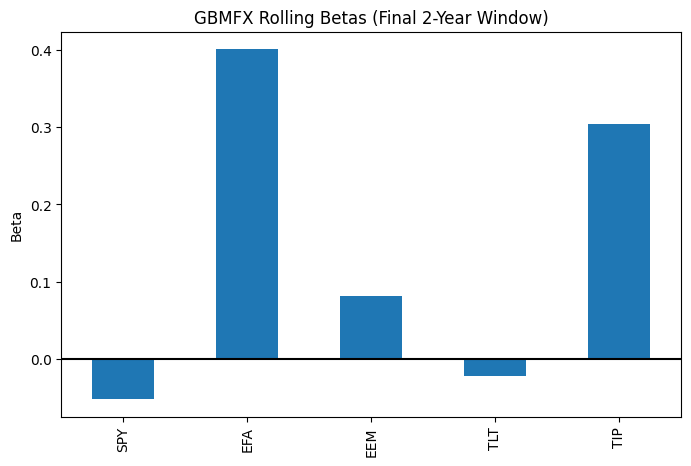

In [69]:
WINDOW = 104
factors = ['SPY', 'EFA', 'EEM', 'TLT', 'TIP']

X = benchmarks[factors].sub(rf_weekly, axis=0)
y = gmo['GBMFX'] - rf_weekly

data = pd.concat([y.rename('GBMFX'), X], axis=1).dropna()

rolling_betas = []

for i in range(WINDOW, len(data) + 1):
    sample = data.iloc[i-WINDOW:i]

    model = LinearRegression()
    model.fit(sample[factors], sample['GBMFX'])

    rolling_betas.append(model.coef_)

rolling_betas = pd.DataFrame(
    rolling_betas,
    index=data.index[WINDOW-1:],
    columns=factors)

# Bar chart
rolling_betas.iloc[-1].plot(kind='bar', figsize=(8, 5))
plt.title('GBMFX Rolling Betas (Final 2-Year Window)')
plt.ylabel('Beta')
plt.axhline(0, color='black')
plt.show()

### 5.

Plot the exposures and discuss how the strategy has changed over time.

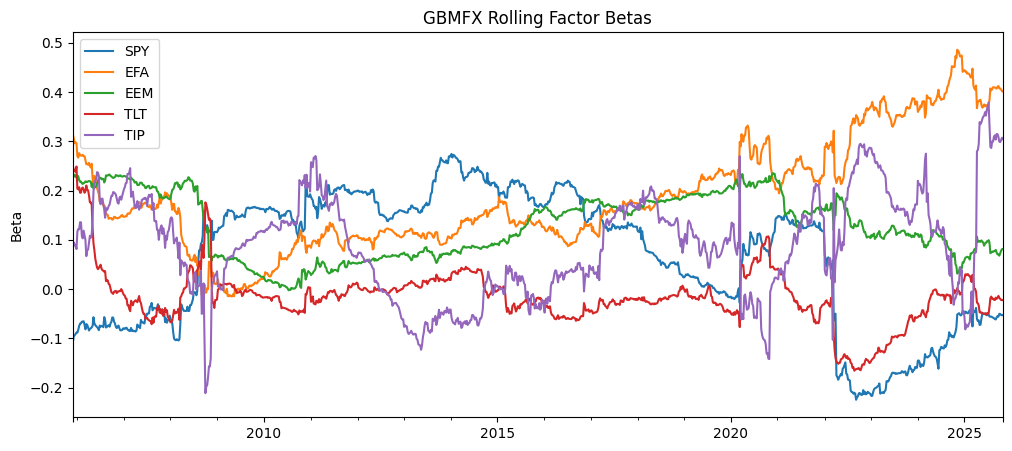

In [72]:
rolling_betas.plot(figsize=(12, 5))
plt.title('GBMFX Rolling Factor Betas')
plt.ylabel('Beta')
plt.show()

GBMFX's factor exposures have changed substantially over time. In earlier periods (2013–2016), the fund had more exposure to SPY. Since 2022, SPY exposure turned negative (shifting away from equities), while EFA and TIPs have become more prominent.

# 6. Forecasts

The chapter 7 exercise on forecasting `SPY` takes readers through forecast regressions using valuation signals similar to those used by GMO.

### 1.

In `July 2015`, GMO forecasted the following as 7-year annualized mean **real** returns.

#### Footnote:
Their forecasts specify classes and benchmarks. Here, we map those to specific ETFs not specified by GMO. Additionally, we do not track every forecast made.

In [73]:
forecasts = pd.DataFrame({
    'SPY': -2.0,
    'EFA': -0.5,
    'EEM': -3.2,
    'TLT': -0.9,
    'TIP': 0,
    'IJR': -2,
    'GWX': -1.1,
    'EMB': 2.1,
    'BWX': -2.8
},index=['forecast']).T

forecasts /= 100
forecasts.style.format('{:.1%}',na_rep='')

,forecast
SPY,-2.0%
EFA,-0.5%
EEM,-3.2%
TLT,-0.9%
TIP,0.0%
IJR,-2.0%
GWX,-1.1%
EMB,2.1%
BWX,-2.8%


Use the `benchmarks` data to calculate the realized 7-year **nominal excess** return on these assets. You have ETF proxies for most of the categories, and ignore those for which you do not.

#### Note
Using nominal excess instead of real total should not greatly impact the analysis.

In [74]:
assets = forecasts.index.intersection(benchmarks.columns)

rets_7yr = benchmarks.loc['2015-07':'2022-07', assets]
rf_7yr = rf_weekly.loc['2015-07':'2022-07']
excess_7yr = rets_7yr.sub(rf_7yr, axis=0).dropna()

realized = (1 + excess_7yr).prod() ** (52 / len(excess_7yr)) - 1

comparison = pd.DataFrame({
    'GMO Forecast': forecasts.loc[assets, 'forecast'],
    'Realized Excess Return': realized})

display(comparison.style.format('{:.2%}'))

,GMO Forecast,Realized Excess Return
SPY,-2.00%,10.99%
EFA,-0.50%,2.07%
EEM,-3.20%,1.23%
TLT,-0.90%,1.57%
TIP,0.00%,2.44%
IJR,-2.00%,8.18%
GWX,-1.10%,2.52%
EMB,2.10%,0.59%
BWX,-2.80%,-1.46%


### 2.

* Given your out-of-sample results from the forecasting exercise, are you surprised by GMO's forecast accuracy?
* Could a dynamic strategy based on these signals have avoided the 2000–2011 equity underperformance?
* How does the in-sample vs. out-of-sample distinction relate to GMO's reliance on long-run mean reversion?

1. Are you surprised by GMO's forecast accuracy?

No. The forecasting exercise showed negative OOS R^2 values which makes sense since beating the naive forecast for returns is very hard to do. GMO significantly underestimated returns, especially for SPY (−2% forecast vs. 10.99% realized).

2. Could a dynamic strategy have avoided the 2000–2011 equity underperformance?

If there were signals that identified overvalued equities and shifted investments toward bonds then maybe, but the OOS performance tells us that it would be alomst impossible to time that

3. How does in-sample vs. out-of-sample relate to GMO's reliance on mean reversion?

GMO relies on the idea that asset valuations eventually revert to historical norms. This relationship appears strong in-sample, but the negative OOS R^2 values suggest that mean reversion is unreliable for forecasting returns.